In [4]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

The Figures use the data of Fig. 10 (`../Fig-10-LER/data`).

In [5]:
# import data of Fig. 10 from csv file
data_ISM    = pd.read_csv(Path("../Fig-10-LER/data") / "ism.csv")
data_ISM_PP = pd.read_csv(Path("../Fig-10-LER/data") / "ism_pp.csv")

data_GSM    = pd.read_csv(Path("../Fig-10-LER/data") / "gsm.csv")
data_GSM_PP = pd.read_csv(Path("../Fig-10-LER/data") / "gsm_pp.csv")

# decoder configurations in the order of the legend
data = {"MWPM + PP": data_GSM_PP, "MWPM": data_GSM, "ISM + PP": data_ISM_PP, "ISM": data_ISM}

In [6]:
def sub_data(df, p_min=None, p_max=None, distances=None):
    sub = df.copy()
    if p_min:
        sub = sub[sub["p_phys"] >= p_min]
    if p_max:
        sub = sub[sub["p_phys"] <= p_max]
    if distances:
        sub = sub[sub["distance"].isin(distances)]
    return sub

In [7]:
STYLES = {
    "MWPM + PP": dict(color='blue',    linestyle='solid',   marker='o', markersize=12),
    "MWPM":      dict(color='red',     linestyle='dashed',  marker='D', markersize=12),
    "ISM + PP": dict(color='green',   linestyle='dotted',  marker='s', markersize=12),
    "ISM":      dict(color='magenta', linestyle='dashdot', marker='*', markersize=18),
}

def plot_effect_of_pp(data, x_col, x_label, ax, legend_loc, save_path=None):
    for label, df in data.items():
        df = df.sort_values(x_col)
        ax.plot(df[x_col], df['p_log'], label=label, linewidth=4, **STYLES[label])

    ax.legend(loc=legend_loc, prop={'size': 28})
    plt.xticks(fontsize=28)
    plt.yticks(fontsize=28)
    plt.xlabel(x_label, size=28)
    plt.ylabel('Code failure rate', size=28)
    plt.yscale('log')
    # Thicker box around plot (spines)
    for spine in ax.spines.values():
        spine.set_linewidth(3)  # Adjust thickness as needed
    # Thicker major ticks
    ax.tick_params(axis='both', which='major', width=3, length=12)  # length is optional
    # Thicker minor ticks
    ax.tick_params(axis='both', which='minor', width=1.5, length=8)  # Adjust as needed
    if save_path is not None:
        ax.figure.savefig(save_path, format='pdf', bbox_inches='tight')
    plt.show()

# Fig a):
Code failure rate vs. physical error probability below the threshold, at a fixed code distance $d = 15$.

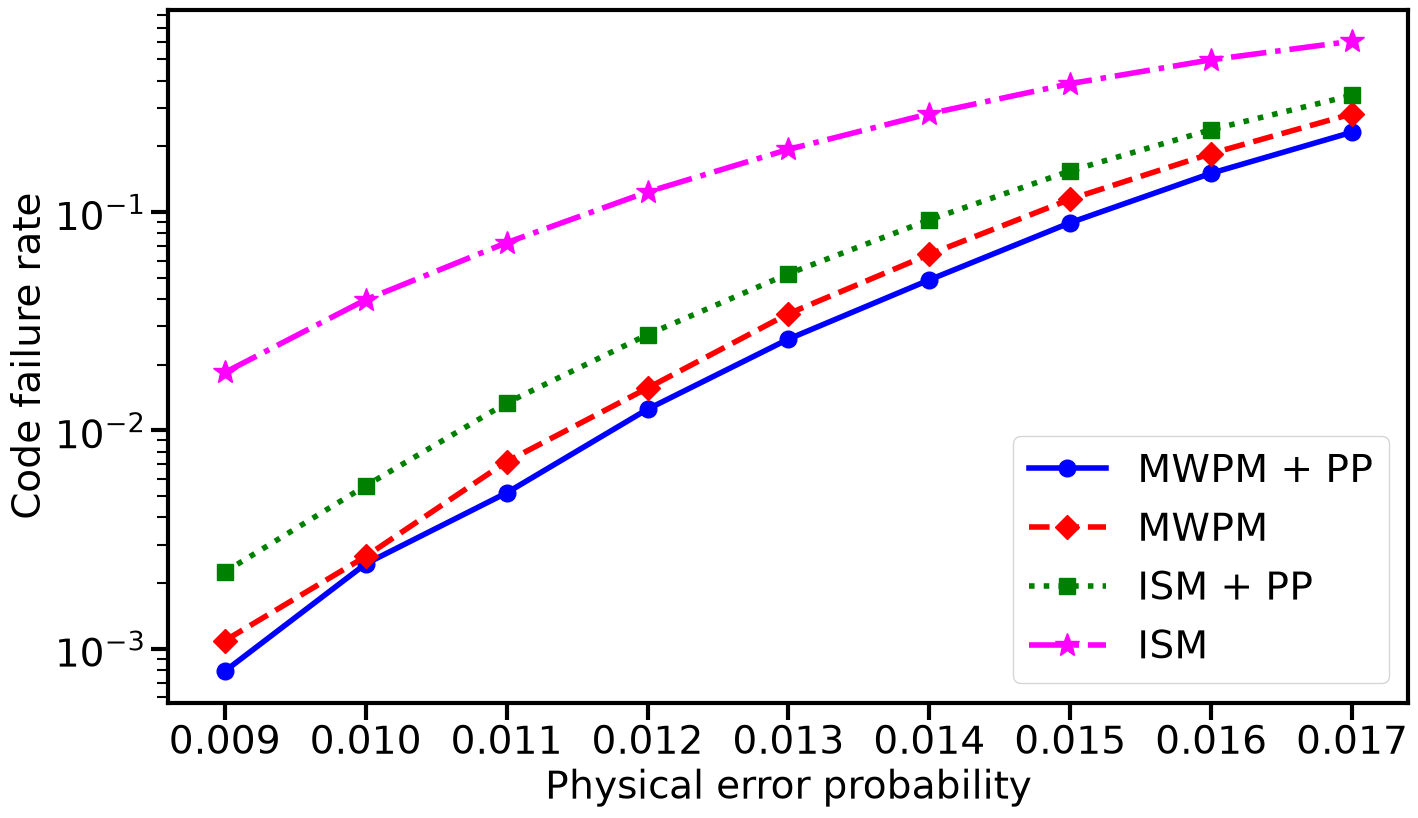

In [8]:
d = 15
p_min, p_max = 0.009, 0.017

fig, ax = plt.subplots(figsize=(16, 9))
sub = {label: sub_data(df, p_min=p_min, p_max=p_max, distances=[d]) for label, df in data.items()}
plot_effect_of_pp(sub, 'p_phys', 'Physical error probability', ax, legend_loc='lower right', save_path=Path("./Fig-effect-of-PP-a.pdf"))

# Fig b):
Code failure rate vs. code distance at a fixed physical error probability

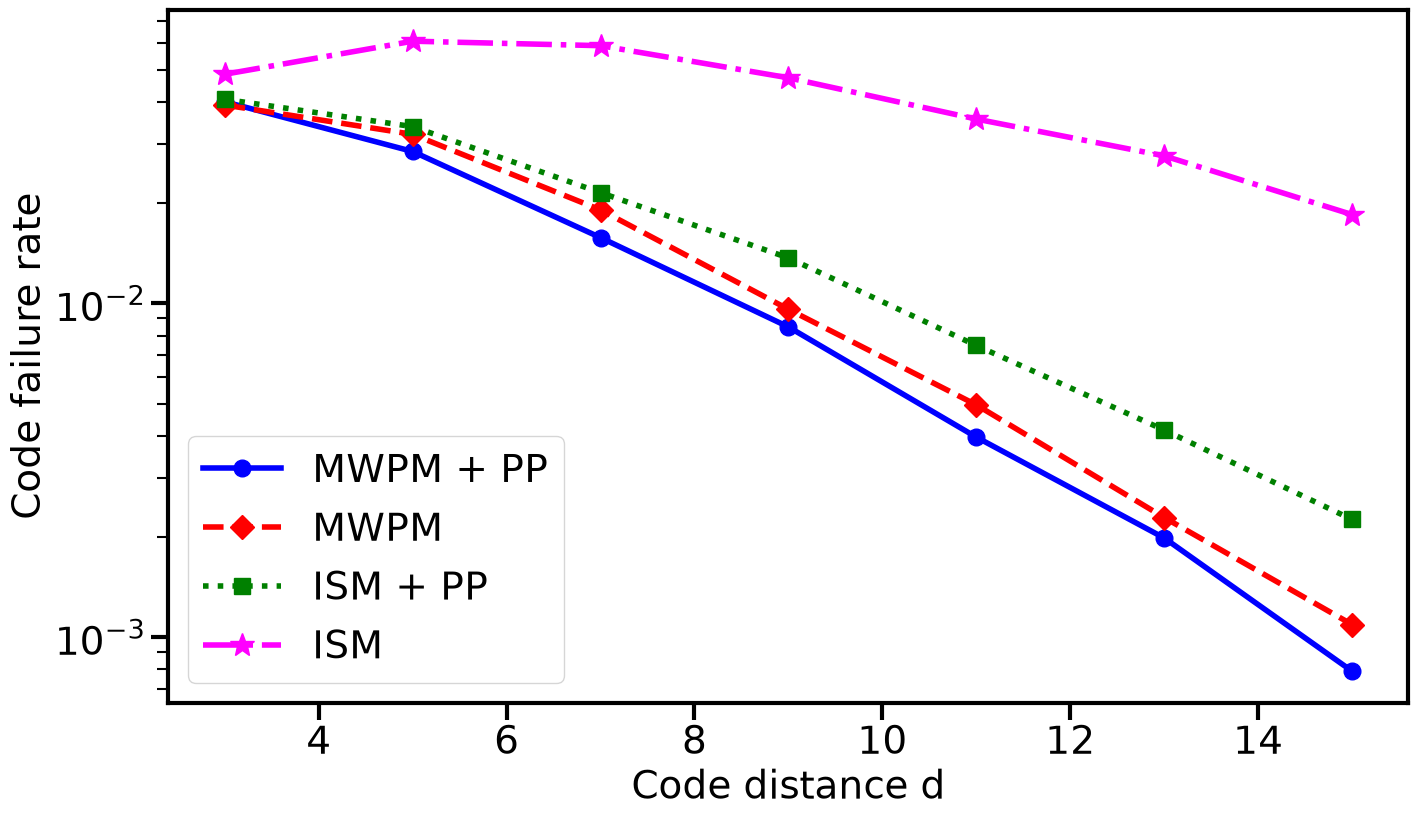

In [9]:
p = 0.009  # physical error probability of Fig b)

fig, ax = plt.subplots(figsize=(16, 9))
sub = {label: df[np.isclose(df['p_phys'], p)] for label, df in data.items()}
plot_effect_of_pp(sub, 'distance', 'Code distance d', ax, legend_loc='lower left', save_path=Path("./Fig-effect-of-PP-b.pdf"))